,group,converted
0,A,0
1,A,1
2,A,0
3,A,0
4,A,0


Conversion A: 13.00%
Conversion B: 16.00%
Absolute difference (B - A): 3.00%
Relative change: 23.08%
95% confidence interval A: 8.34% - 17.66%
95% confidence interval B: 10.92% - 21.08%


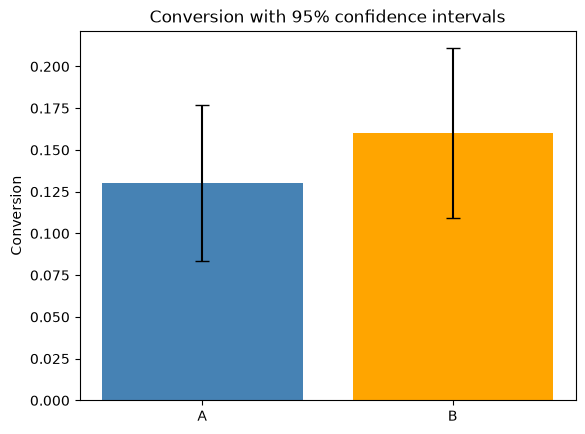

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

n = 200
group_a = np.random.binomial(1, 0.12, n)
group_b = np.random.binomial(1, 0.16, n)
data = pd.DataFrame({
    "group": ["A"] * n + ["B"] * n,
    "converted": np.concatenate([group_a, group_b])
})
display(data.head())

conversion_a = group_a.mean()
conversion_b = group_b.mean()
difference = conversion_b - conversion_a
relative_change = difference / conversion_a

print(f"Conversion A: {conversion_a:.2%}")
print(f"Conversion B: {conversion_b:.2%}")
print(f"Absolute difference (B - A): {difference:.2%}")
print(f"Relative change: {relative_change:.2%}")

margin_a = 1.96 * np.sqrt(conversion_a * (1 - conversion_a) / n)
margin_b = 1.96 * np.sqrt(conversion_b * (1 - conversion_b) / n)
print(f"95% confidence interval A: {(conversion_a - margin_a):.2%} - {(conversion_a + margin_a):.2%}")
print(f"95% confidence interval B: {(conversion_b - margin_b):.2%} - {(conversion_b + margin_b):.2%}")

plt.bar(["A", "B"], [conversion_a, conversion_b], color=["steelblue", "orange"])
plt.errorbar(["A", "B"], [conversion_a, conversion_b], yerr=[margin_a, margin_b], fmt="none", color="black", capsize=5)
plt.title("Conversion with 95% confidence intervals")
plt.ylabel("Conversion")
plt.show()